# 04 · Business impact: what a better forecast means in the kitchen

**Question:** what does the forecast error mean in covers, for whom is the forecast reliable, and when should a manager not trust it?

**Data:** the 6 validation weeks (notebook 03), never used for training.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

v = pd.read_csv("../data/processed/validation_predictions.csv", parse_dates=["visit_date"])
DOW = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

def clean_axes(ax, keep="bottom"):
    """Light chart style: no top/right frame, soft grid."""
    for side in ["top", "right", "left", "bottom"]:
        ax.spines[side].set_visible(side == keep)
    ax.spines[keep].set_color("#ccc")
    ax.tick_params(length=0, labelsize=9)

v["err_base"] = v["pred_last_week"] - v["visitors"]
v["err_model"] = v["pred_model"].clip(lower=0) - v["visitors"]
print(v.shape)

(30035, 15)


## 4.1 The error in covers
For a kitchen, what matters is how many covers the plan is off by: **over-forecast** = food prepared and not served, **under-forecast** = dishes running out or guests waiting.

In [2]:
def cover_summary(err):
    return {
        "avg_abs_error_covers": round(err.abs().mean(), 2),
        "over_forecast_covers": round(err.clip(lower=0).sum()),
        "under_forecast_covers": round((-err).clip(lower=0).sum()),
    }

open_days_per_week = v.groupby("air_store_id").size().mean() / 6
covers = pd.DataFrame({
    "Same as last week": cover_summary(v["err_base"]),
    "Model": cover_summary(v["err_model"]),
}).T
covers["abs_error_per_restaurant_week"] = (covers["avg_abs_error_covers"] * open_days_per_week).round(1)
print(f"Average open days per restaurant per week: {open_days_per_week:.1f}")
covers

Average open days per restaurant per week: 6.1


,avg_abs_error_covers,over_forecast_covers,under_forecast_covers,abs_error_per_restaurant_week
Same as last week,9.25,139129.0,138569.0,56.1
Model,7.02,75789.0,135003.0,42.5


## 4.2 Error by day of the week

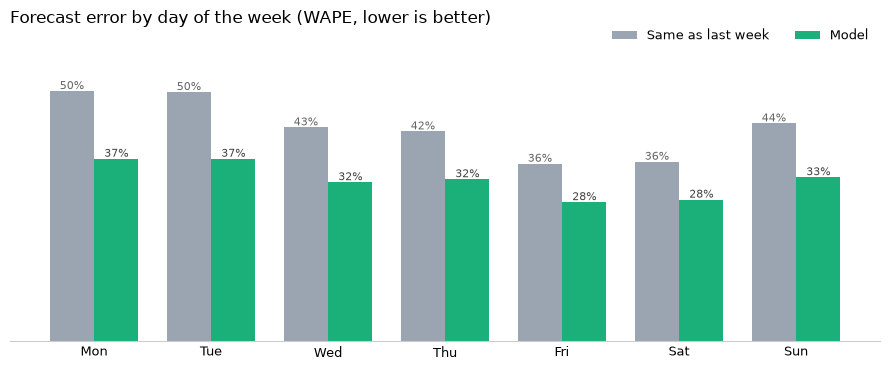

,Same as last week,Model
day_of_week,,
Monday,50.2,36.6
Tuesday,50.0,36.6
Wednesday,42.9,31.9
Thursday,42.1,32.5
Friday,35.6,27.9
Saturday,36.0,28.4
Sunday,43.7,32.9


In [3]:
def wape(g, col):
    return (g[col].abs().sum() / g["visitors"].sum()) * 100

by_dow = pd.DataFrame({
    "Same as last week": v.groupby("day_of_week").apply(wape, "err_base", include_groups=False),
    "Model": v.groupby("day_of_week").apply(wape, "err_model", include_groups=False),
}).reindex(DOW).round(1)

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(DOW)); w = 0.38
ax.bar(x - w / 2, by_dow["Same as last week"], w, color="#9aa5b1", label="Same as last week")
ax.bar(x + w / 2, by_dow["Model"], w, color="#1baf7a", label="Model")
for i, (a, b) in enumerate(zip(by_dow["Same as last week"], by_dow["Model"])):
    ax.text(i - w / 2, a + 0.4, f"{a:.0f}%", ha="center", fontsize=8, color="#666")
    ax.text(i + w / 2, b + 0.4, f"{b:.0f}%", ha="center", fontsize=8, color="#444")
ax.set_xticks(x)
ax.set_xticklabels([d[:3] for d in DOW])
ax.set_ylim(0, by_dow.values.max() * 1.15)
clean_axes(ax)
ax.yaxis.set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2)
ax.set_title("Forecast error by day of the week (WAPE, lower is better)", loc="left", fontsize=12, pad=22)
plt.tight_layout()
plt.savefig("../figures/error_by_weekday.png", dpi=150, bbox_inches="tight")
plt.show()
by_dow

## 4.3 Small vs large restaurants

In [4]:
size = v.groupby("air_store_id")["visitors"].median()
v["size_group"] = v["air_store_id"].map(pd.qcut(size, 4, labels=["1. Smallest 25%", "2.", "3.", "4. Largest 25%"]))
by_size = v.groupby("size_group", observed=True).apply(
    lambda g: pd.Series({
        "median_covers": g["visitors"].median(),
        "WAPE_base_%": round(wape(g, "err_base"), 1),
        "WAPE_model_%": round(wape(g, "err_model"), 1),
        "MAE_model_covers": round(g["err_model"].abs().mean(), 1),
    }), include_groups=False)
by_size

,median_covers,WAPE_base_%,WAPE_model_%,MAE_model_covers
size_group,,,,
1. Smallest 25%,7.0,57.9,42.8,3.7
2.,15.0,51.2,37.0,6.0
3.,23.0,42.6,31.4,7.9
4. Largest 25%,36.0,33.9,27.4,10.7


Small restaurants usually have a higher **percentage** error (one table more or less is a big share of a quiet day) but a smaller error in **covers**. Both views matter: percentages for comparing restaurants, covers for planning the kitchen.

## 4.4 Holidays and restaurants with online reservations

In [5]:
segments = []
for name, m in {
    "Normal days": v["holiday_flg"] == 0,
    "Public holidays": v["holiday_flg"] == 1,
    "Restaurants with reservation data": v["has_reservations"] == 1,
    "Restaurants without reservation data": v["has_reservations"] == 0,
    "Extreme days (>10x median)": v["is_extreme"] == 1,
}.items():
    g = v[m]
    if len(g):
        segments.append({"segment": name, "restaurant_days": len(g),
                         "WAPE_base_%": round(wape(g, "err_base"), 1),
                         "WAPE_model_%": round(wape(g, "err_model"), 1),
                         "bias_model_%": round((g["pred_model"].clip(lower=0).sum() / g["visitors"].sum() - 1) * 100, 1)})
segments = pd.DataFrame(segments)
segments

,segment,restaurant_days,WAPE_base_%,WAPE_model_%,bias_model_%
0,Normal days,29482,41.7,31.7,-8.8
1,Public holidays,553,51.7,38.0,-13.9
2,Restaurants with reservation data,12403,43.9,32.2,-6.8
3,Restaurants without reservation data,17632,40.3,31.5,-10.7
4,Extreme days (>10x median),10,91.4,89.6,-89.6


## Summary

In [6]:
b, m = covers.loc["Same as last week"], covers.loc["Model"]
print(f"Average error per restaurant-day: {b['avg_abs_error_covers']} covers (last week rule) -> "
      f"{m['avg_abs_error_covers']} covers (model)")
print(f"Per restaurant per week: {b['abs_error_per_restaurant_week']} -> {m['abs_error_per_restaurant_week']} covers misplanned")
print(f"Over-forecast covers (prepared, not served): {b['over_forecast_covers']:,.0f} -> {m['over_forecast_covers']:,.0f}")
print(f"Under-forecast covers (missing): {b['under_forecast_covers']:,.0f} -> {m['under_forecast_covers']:,.0f}")
print(f"Hardest weekday for the model: {by_dow['Model'].idxmax()} ({by_dow['Model'].max()}%), "
      f"easiest: {by_dow['Model'].idxmin()} ({by_dow['Model'].min()}%)")
print(by_size.to_string())
print(segments.to_string(index=False))

Average error per restaurant-day: 9.25 covers (last week rule) -> 7.02 covers (model)
Per restaurant per week: 56.1 -> 42.5 covers misplanned
Over-forecast covers (prepared, not served): 139,129 -> 75,789
Under-forecast covers (missing): 138,569 -> 135,003
Hardest weekday for the model: Monday (36.6%), easiest: Friday (27.9%)
                 median_covers  WAPE_base_%  WAPE_model_%  MAE_model_covers
size_group                                                                 
1. Smallest 25%            7.0         57.9          42.8               3.7
2.                        15.0         51.2          37.0               6.0
3.                        23.0         42.6          31.4               7.9
4. Largest 25%            36.0         33.9          27.4              10.7
                             segment  restaurant_days  WAPE_base_%  WAPE_model_%  bias_model_%
                         Normal days            29482         41.7          31.7          -8.8
                     Publi

## Findings

1. **Fewer covers misplanned.** The average error drops from 9.25 to 7.02 covers per restaurant-day, from 56.1 to 42.5 covers per restaurant per week (−24%) compared with "same as last week".
2. **Less food prepared and not served, not fewer shortages.** Over-forecast covers fall by 45% (139,129 → 75,789), while under-forecast covers barely change (138,569 → 135,003). This is the effect of the model's negative bias (−8.9%).
3. **Mondays are hardest** (36.6% WAPE), **Fridays easiest** (27.9%).
4. **Small restaurants:** the highest error in percentage (42.8% for the smallest quarter vs 27.4% for the largest) but the smallest in covers (3.7 vs 10.7 per day).
5. **Holidays** are harder (38.0% vs 31.7% on normal days) and more under-forecast (−13.9%).
6. **Events cannot be forecast from history:** on the 10 extreme days in the validation period the error is ~90%.

## Recommendations

1. **Plan prep and staff on the forecast rather than on "last week":** 24% fewer covers misplanned and almost half of the food prepared and not served.
2. **Correct the bias before use.** The model under-forecasts by ~9% (~14% on holidays): apply a scaling correction or a Poisson loss, or add a safety margin on items that keep.
3. **Feed online reservations into the forecast, never use them as the forecast.** They improve accuracy where available, but they cover only about one fifth of covers.
4. **Keep a manual check for events, holidays and Mondays,** where history says least about tomorrow.

**Caveats:** 6 validation weeks only; no data on menus, prices, weather or local events; closed days inferred from missing records.